<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp15_Iris_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 15: Iris Flower Classification using Naive Bayes
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement Iris Flower Classification using the Naive Bayes classifier.

## Background
**Gaussian Naive Bayes** assumes each feature follows a normal distribution within a class and that features are independent given the class. Prediction: `class = argmax_c [ log P(c) + sum_i log N(x_i | mu_ci, sigma_ci^2) ]`. It is very fast, works with little data and returns class probabilities.



## Setup: Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
Load the Iris data from scikit-learn and save as CSV.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
frame = iris.frame.copy()
frame["species"] = frame["target"].map(dict(enumerate(iris.target_names)))
frame = frame.drop(columns="target")
frame.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
frame.to_csv("iris.csv", index=False)
print("Saved iris.csv", frame.shape)

Saved iris.csv (150, 5)


## Step 2: Data Loading

In [ ]:
df = pd.read_csv("iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 3: Data Preprocessing
Check quality, encode labels and split. Naive Bayes does not need feature scaling (each feature is modelled separately).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("Missing:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
le = LabelEncoder()
y = le.fit_transform(df["species"])
X = df[features]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Classes:", list(le.classes_), "| Train:", X_train.shape, "Test:", X_test.shape)

Missing: 0 | Duplicates: 1
Classes: ['setosa', 'versicolor', 'virginica'] | Train: (120, 4) Test: (30, 4)


## Step 4: Exploratory Data Analysis (EDA)
Gaussian NB assumes bell-shaped class-conditional distributions - let's check that assumption visually and with a normality test.

              count  mean   std  min  25%   50%  75%  max
sepal_length  150.0  5.84  0.83  4.3  5.1  5.80  6.4  7.9
sepal_width   150.0  3.06  0.44  2.0  2.8  3.00  3.3  4.4
petal_length  150.0  3.76  1.77  1.0  1.6  4.35  5.1  6.9
petal_width   150.0  1.20  0.76  0.1  0.3  1.30  1.8  2.5


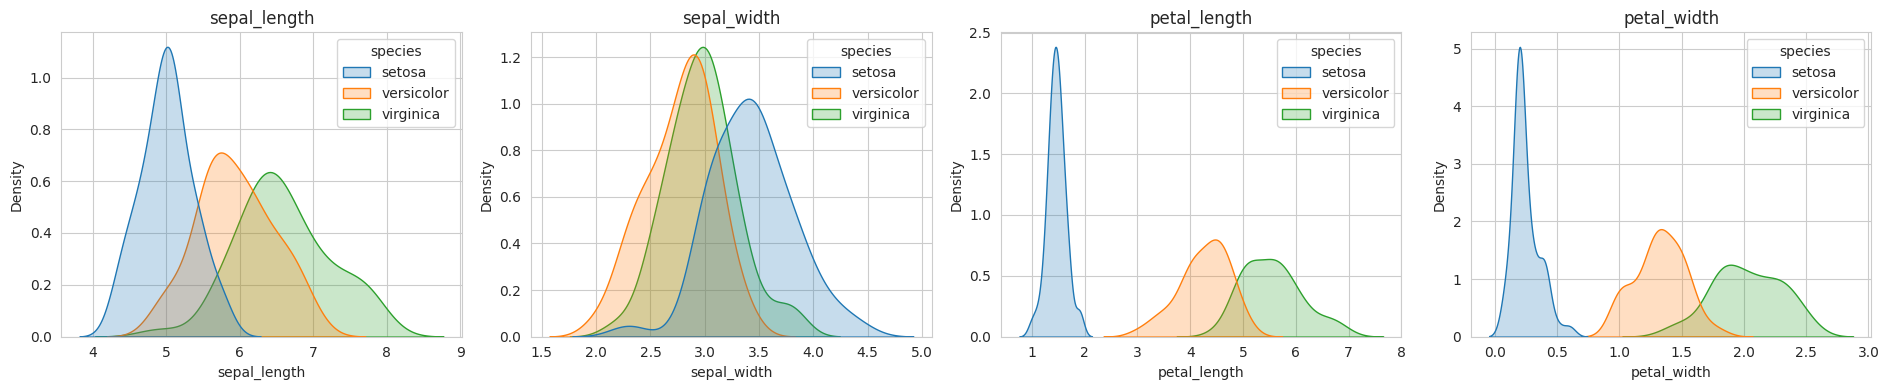


Shapiro-Wilk p-values (p > 0.05 -> consistent with a normal distribution):
 feature     petal_length  petal_width  sepal_length  sepal_width
species                                                         
setosa             0.055        0.000         0.460        0.272
versicolor         0.158        0.027         0.465        0.338
virginica          0.110        0.087         0.258        0.181


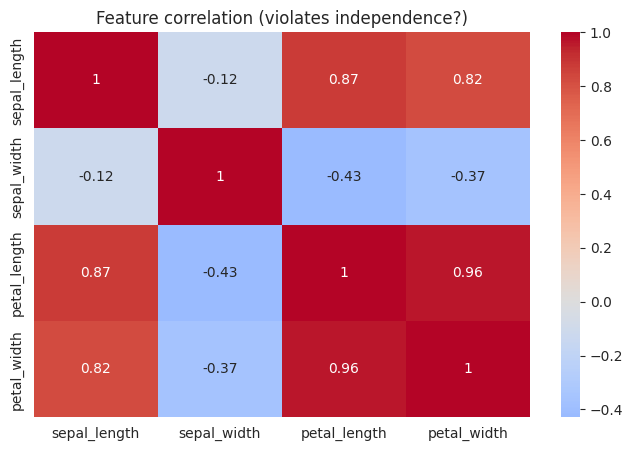

In [ ]:
print(df.describe().T.round(2))
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, features):
    sns.kdeplot(data=df, x=col, hue="species", fill=True, common_norm=False, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

from scipy import stats
rows = []
for sp, g in df.groupby("species"):
    for col in features:
        rows.append({"species": sp, "feature": col, "Shapiro p-value": round(stats.shapiro(g[col])[1], 3)})
pvals = pd.DataFrame(rows).pivot(index="species", columns="feature", values="Shapiro p-value")
print("\nShapiro-Wilk p-values (p > 0.05 -> consistent with a normal distribution):\n", pvals)

sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", center=0); plt.title("Feature correlation (violates independence?)"); plt.show()

## Step 5: Model Training
First we compute the Bayes calculation by hand (priors, class means and variances), then confirm that it equals scikit-learn's `GaussianNB`. We then tune `var_smoothing` with grid search.

In [ ]:
from sklearn.naive_bayes import GaussianNB

classes = np.unique(y_train)
priors = {c: np.mean(y_train == c) for c in classes}
means = {c: X_train[y_train == c].mean().values for c in classes}
varis = {c: X_train[y_train == c].var(ddof=0).values for c in classes}

def manual_posterior(x):
    logp = {}
    for c in classes:
        log_lik = -0.5 * np.sum(np.log(2 * np.pi * varis[c]) + (x - means[c]) ** 2 / varis[c])
        logp[c] = np.log(priors[c]) + log_lik
    m = max(logp.values())
    unnorm = {c: np.exp(v - m) for c, v in logp.items()}
    s = sum(unnorm.values())
    return np.array([unnorm[c] / s for c in classes])

print("Priors:", {le.classes_[c]: round(p, 3) for c, p in priors.items()})
print("Class means (petal_length):", {le.classes_[c]: round(means[c][2], 2) for c in classes})

nb = GaussianNB().fit(X_train, y_train)
sample = X_test.iloc[0].values
print("\nManual posterior :", manual_posterior(sample).round(4))
print("sklearn posterior:", nb.predict_proba([sample])[0].round(4))

Priors: {'setosa': np.float64(0.333), 'versicolor': np.float64(0.333), 'virginica': np.float64(0.333)}
Class means (petal_length): {'setosa': np.float64(1.48), 'versicolor': np.float64(4.25), 'virginica': np.float64(5.58)}

Manual posterior : [1. 0. 0.]
sklearn posterior: [1. 0. 0.]


In [ ]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(GaussianNB(), {"var_smoothing": np.logspace(-12, 0, 13)}, cv=5).fit(X_train, y_train)
print("Best var_smoothing:", grid.best_params_["var_smoothing"], "| CV accuracy:", round(grid.best_score_, 4))
nb = grid.best_estimator_

Best var_smoothing: 1e-12 | CV accuracy: 0.9583


## Step 6: Model Evaluation

Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

10-fold CV accuracy: mean = 0.9533 std = 0.0521


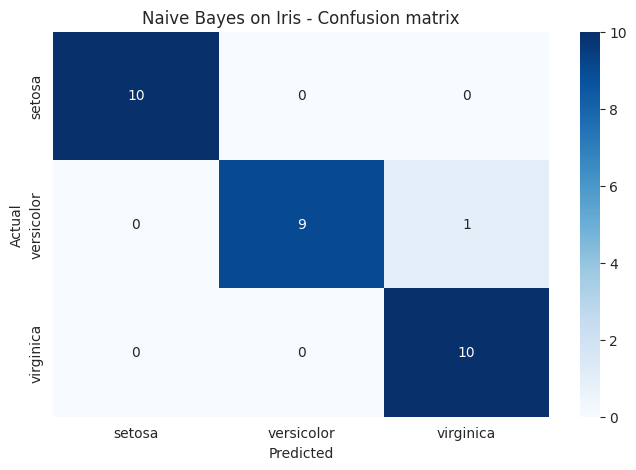

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold

y_pred = nb.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=le.classes_))
cv = cross_val_score(GaussianNB(), X, y, cv=StratifiedKFold(10, shuffle=True, random_state=42))
print("10-fold CV accuracy: mean =", cv.mean().round(4), "std =", cv.std().round(4))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Naive Bayes on Iris - Confusion matrix"); plt.show()

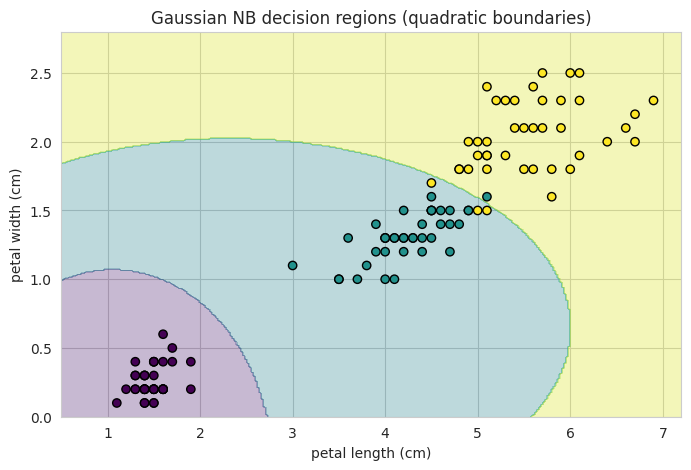

In [ ]:
# Decision regions on the two petal features
nb2 = GaussianNB().fit(X_train[["petal_length", "petal_width"]], y_train)
xx, yy = np.meshgrid(np.linspace(0.5, 7.2, 300), np.linspace(0, 2.8, 300))
Z = nb2.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=["petal_length", "petal_width"])).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
plt.scatter(X_train["petal_length"], X_train["petal_width"], c=y_train, cmap="viridis", edgecolor="k")
plt.xlabel("petal length (cm)"); plt.ylabel("petal width (cm)"); plt.title("Gaussian NB decision regions (quadratic boundaries)"); plt.show()

## Step 7: Prediction on New Data

In [ ]:
new_flowers = pd.DataFrame([[5.0, 3.4, 1.5, 0.2], [6.1, 2.8, 4.7, 1.3], [7.2, 3.0, 5.9, 2.1]], columns=features)
for row, p, pr in zip(new_flowers.values, nb.predict(new_flowers), nb.predict_proba(new_flowers)):
    print(row, "->", le.classes_[p], dict(zip(le.classes_, pr.round(3))))

[5.  3.4 1.5 0.2] -> setosa {'setosa': np.float64(1.0), 'versicolor': np.float64(0.0), 'virginica': np.float64(0.0)}
[6.1 2.8 4.7 1.3] -> versicolor {'setosa': np.float64(0.0), 'versicolor': np.float64(0.998), 'virginica': np.float64(0.002)}
[7.2 3.  5.9 2.1] -> virginica {'setosa': np.float64(0.0), 'versicolor': np.float64(0.0), 'virginica': np.float64(1.0)}


## Conclusion
Gaussian Naive Bayes reaches roughly 93-97% accuracy on Iris even though petal and sepal measurements are correlated (violating the independence assumption) - Naive Bayes often works well despite this. The hand-computed posterior matched scikit-learn exactly. Compared with K-NN (Experiment 12) it is faster and gives calibrated-looking probabilities, with similar accuracy on this dataset.